# Generating noise

**Noise** is a *row-wise* perturbation of the observed values: each
affected row gets its own random deviation, drawn independently
(in contrast to drift, where one systematic shift is applied to all
affected rows). Use noise to make a pipeline robust to measurement
error, sensor jitter, or rounding — the *signal* is still there, but
each observation is a bit off.

This notebook shows the **two levers** available in badgers:

1. **Acting on the observation process** — add noise directly to the
   observed values (`AdditiveNoiseGenerator`,
   `GaussianNoiseClassesGenerator`). These generators *do not use a
   DGP* and nothing propagates: the value is changed exactly where
   the noise lands.
2. **Acting on the data-generating process (DGP)** — inject noise at a
   node of a *fitted causal model* and let it **propagate** to the
   descendants (`CausalNoiseGenerator`).

Both accept a **selector** to decide which rows are affected
(see the *Understanding badgers* notebook for the selector contract).


## Goal

Corrupt values with additive noise: per-class white noise, noise drawn from any scipy distribution, and noise injected into a causal graph with descendants recomputed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng
from scipy.stats import norm
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.noise import AdditiveNoiseGenerator, GaussianNoiseClassesGenerator

rng = default_rng(seed=0)


In [2]:
from _shared import plot_noise  # from docs/tutorials/tabular-data/_shared.py

## Load and prepare data

We first load an existing dataset from `sklearn.datasets`. The class
values are stored as a **column of `X`** (the `y` argument is
deprecated as a data carrier), so plotting uses the explicit vector
`cls`.


In [3]:
X, y = make_blobs(centers=4, random_state=0, cluster_std=0.25)
# classes are a column of X (y is deprecated as a data carrier)
Xc = np.column_stack([X, y])
column_mapping = {'f0': 0, 'f1': 1, 'cls': 2}
cls = Xc[:, column_mapping['cls']]   # explicit class vector for plotting
print(X.shape, '->', Xc.shape)

(100, 2) -> (100, 3)


## Part A — Acting on the observation process (no DGP)

### Add noise to all values

`AdditiveNoiseGenerator` adds a draw from `distribution` to **every
cell** of `X` — each row gets its own independent deviation.


In [4]:
# norm(scale=0.25): an ABSOLUTE scale -- every cell gets an N(0, 0.25) draw,
# independent of the column's own std. Contrast with the sigma-relative
# noise_std of the causal generator in Part B.
gen = AdditiveNoiseGenerator(random_generator=rng)
Xt, _ = gen.generate(X.copy(), None, distribution=norm(scale=0.25))   # y=None (deprecated slot)
print('shape:', X.shape, '->', Xt.shape)
# verify: the std of each column grew by exactly the noise std
std_before = X.std(axis=0, ddof=0)
std_after = Xt.std(axis=0, ddof=0)
print('std before:', np.round(std_before, 3))
print('std after :', np.round(std_after, 3))
assert np.allclose(std_after, np.sqrt(std_before**2 + 0.25**2), atol=0.05)

shape: (100, 2) -> (100, 2)
std before: [1.506 2.508]
std after : [1.545 2.541]


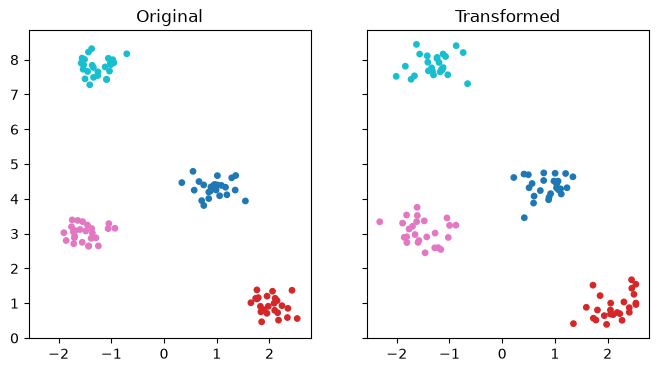

In [5]:
fig, axes = plot_noise(X, cls, Xt)


### Add noise per class

`GaussianNoiseClassesGenerator` combines **two independent parameters**
that are easy to confuse:

* the **selector** decides *which rows* receive noise. It returns one
  boolean mask (or deficit probability) per class value. In the demo
  below, `{'cls': {0: 1., 1: 1., 2: 1., 3: 1.}}` means: *every row of
  every class affected with probability 1* — so all rows are noisy. Set
  a value to `0.5` and half of that class's rows would be noisy
  (Bernoulli-wise); set it to `0.` and that class stays clean.
* `noise_std_per_class` decides *how strong* the noise is **on the
  affected rows**, per class: `{0: 0.1, 1: 0.2, 2: 0.3, 3: 0.4}` makes
  class 3 rows four times noisier than class 0 rows. It has **no**
  effect on *which* rows are noisy.

In short: **selector = who is affected, `noise_std_per_class` = how
badly.**

In [6]:
from badgers.core.selectors import ClassSelector

# WHO is affected: every row of every class is affected (probability 1.0)
selector = ClassSelector('cls', column_mapping, {'cls': {0: 1., 1: 1., 2: 1., 3: 1.}}, rng=rng)

# HOW BADLY: noise std per class value (only applies to affected rows)
gen = GaussianNoiseClassesGenerator(random_generator=rng)
Xt, _ = gen.generate(Xc.copy(), None, selector=selector,
                     noise_std_per_class={0: 0.1, 1: 0.2, 2: 0.3, 3: 0.4})
print('shapes equal (values changed):', Xt.shape == Xc.shape)

shapes equal (values changed): True


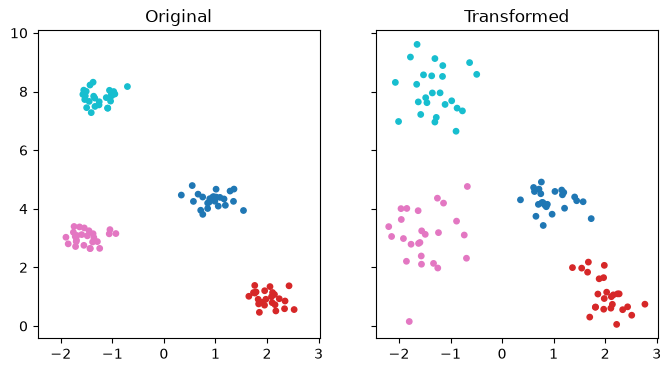

In [7]:
fig, axes = plot_noise(Xc, cls, Xt)


In [8]:
from badgers.generators.tabular_data.noise.causal import CausalNoiseGenerator
import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP


def make_scm(graph):
    scm = gcm.StructuralCausalModel(graph)
    for node in graph.nodes:
        if not list(graph.predecessors(node)):
            scm.set_causal_mechanism(node, gcm.EmpiricalDistribution())
        else:
            scm.set_causal_mechanism(node, gcm.AdditiveNoiseModel(
                prediction_model=gcm.ml.create_linear_regressor()))
    return scm


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part B — Acting on the data-generating process (DGP)

`CausalNoiseGenerator` injects noise at a node of a *fitted causal
model*. The noise perturbs the node's value, and the change
**cascades to the descendants** through the structural equations:
descendant = f(new parent values) + fresh noise. Only downstream nodes
are affected; upstream nodes and untouched rows stay as they were.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP

In [10]:
from _shared import generate_linear_data, draw_graph, plot_2panel  # from docs/tutorials/tabular-data/_shared.py

### 1. Build the causal graph

We use a three-node chain `X -> Y -> Z`. The node names are symbolic;
a `column_mapping` maps them to column positions of `X`.


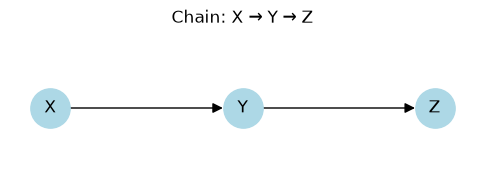

In [11]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


### 2. Generate data from the DAG

Each node is a weighted sum of its parents plus noise, so the data already
carries the causal structure the generator will exploit.

Each node is a weighted sum of its parents plus noise, so the data already
carries the causal structure the generator will exploit.


In [12]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


array([[<Axes: xlabel='X', ylabel='X'>, <Axes: xlabel='Y', ylabel='X'>,
        <Axes: xlabel='Z', ylabel='X'>],
       [<Axes: xlabel='X', ylabel='Y'>, <Axes: xlabel='Y', ylabel='Y'>,
        <Axes: xlabel='Z', ylabel='Y'>],
       [<Axes: xlabel='X', ylabel='Z'>, <Axes: xlabel='Y', ylabel='Z'>,
        <Axes: xlabel='Z', ylabel='Z'>]], dtype=object)

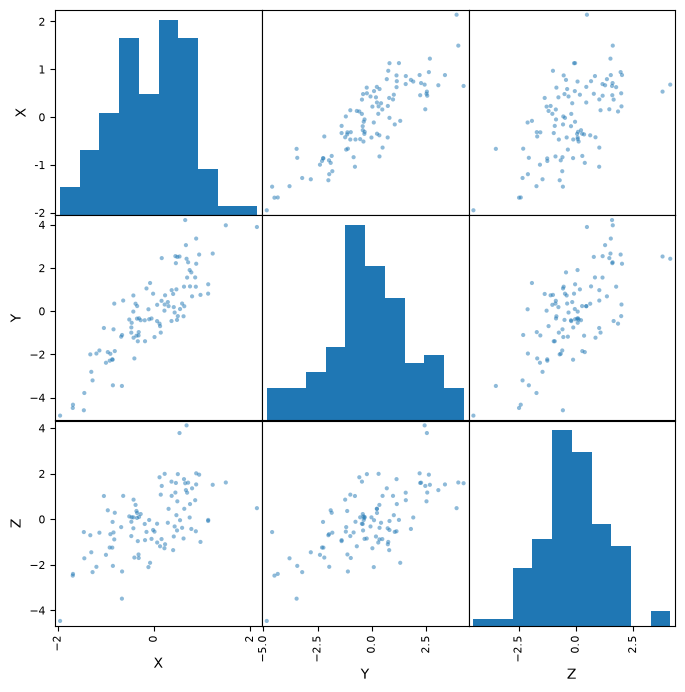

In [13]:
pd.plotting.scatter_matrix(pd.DataFrame(X, columns=column_mapping.keys()), figsize=(8, 8), diagonal='hist')

### 3. Fit the DGP

The `GcmSCMDGP` adapter wraps a `dowhy.gcm.StructuralCausalModel`:
every non-root node's mechanism is a linear `AdditiveNoiseModel` fitted
on the *original* data, root nodes resample the observed values. The
SCM is built with dowhy-gcm's own API (see the `make_scm` helper).

In [14]:
dgp = GcmSCMDGP(make_scm(chain), column_mapping).fit(X.copy())

gen = CausalNoiseGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

Fitting causal mechanism of node Z: 100%|███████████████████████████| 3/3 [00:00<00:00, 141.20it/s]


### 4. Inject causally-propagated noise

We perturb node `Y` and watch the noise propagate to `Z` (but not to
`X`).

In [15]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    n_copies=1,
    noise_std=0.5,  # in sigma units of the column (relative, unlike Part A's absolute scale)
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


In [16]:
# verify the propagation contract
# X is upstream of the perturbed node Y: untouched
assert np.allclose(Xt[:, 0], X[:, 0])
# Y received row-wise noise: larger scatter, same shape
print('std of Y: %.3f -> %.3f' % (X[:, 1].std(ddof=0), Xt[:, 1].std(ddof=0)))
assert Xt[:, 1].std(ddof=0) > X[:, 1].std(ddof=0)
# Z is a descendant of Y: recomputed (values changed)
assert not np.allclose(Xt[:, 2], X[:, 2])


std of Y: 1.904 -> 2.184


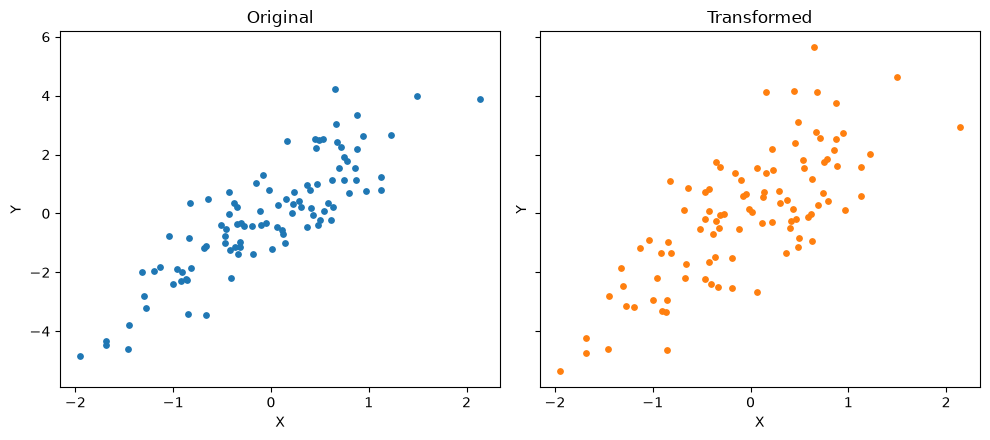

In [17]:
_ = plot_2panel(X, Xt, yt, x_name='X', y_name='Y')

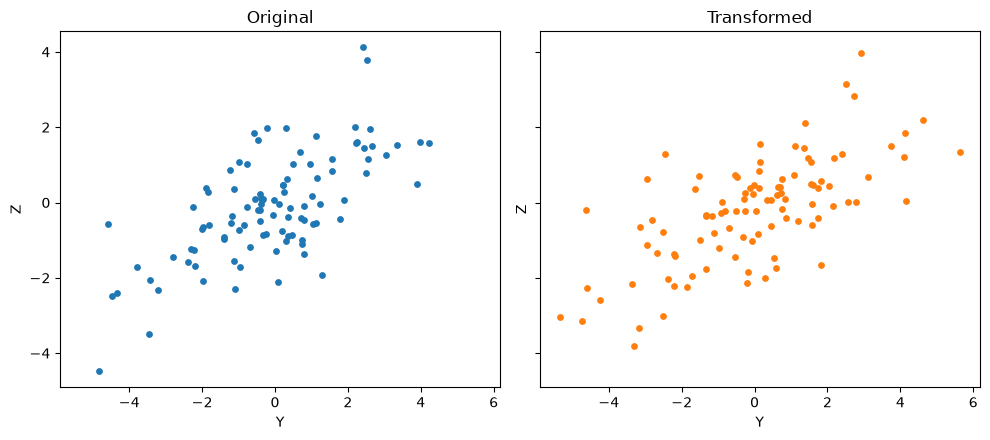

In [18]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Expanding rows (`n_copies`)

Set `n_copies > 1` to *expand* the data: each original row produces
`n_copies` noisy copies. Shape grows (appending mode).

expanded shape: (300, 3)  (from 100 rows)


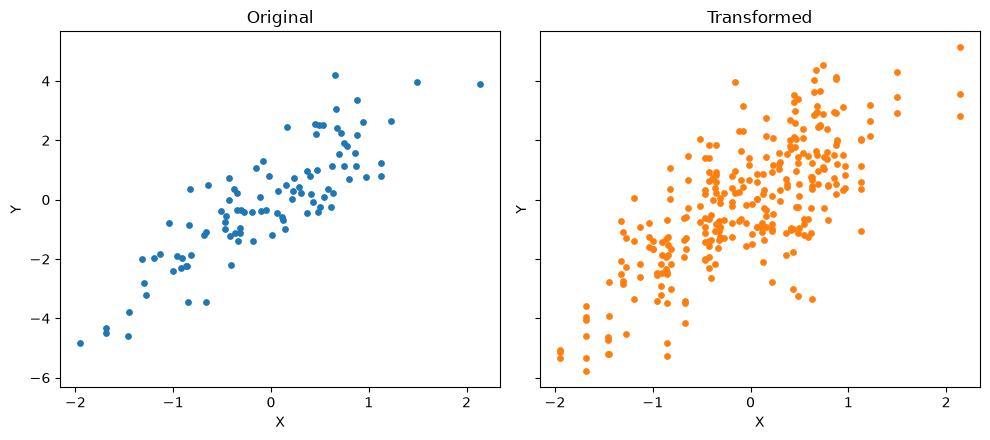

In [19]:
Xt_exp, yt_exp = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    n_copies=3,
    noise_std=0.5,
)
print(f"expanded shape: {Xt_exp.shape}  (from {X.shape[0]} rows)")
_ = plot_2panel(X, Xt_exp, yt_exp, x_name='X', y_name='Y')


## Summary

| Lever | Generator | Uses a DGP? | Propagates? | Selector support |
|---|---|---|---|---|
| observation process | `AdditiveNoiseGenerator` | no | no (values only) | — |
| observation process, per class | `GaussianNoiseClassesGenerator` | no | no (values only) | `ClassSelector` |
| DGP | `CausalNoiseGenerator` | **yes** (fitted) | **yes** — descendants re-evaluated | yes |
* Noise is *row-wise*: each affected row draws its own deviation —
  in contrast to drift, where one systematic shift hits all rows.
* **selector = who is affected** (masks/probabilities per class),
  **`noise_std_per_class` = how strongly** (magnitude per class).
* Causal noise mutates `X` in place — pass `X.copy()` to keep the
  original.


## Takeaways

- Shape is preserved: noise changes values only, never the row count.
- `AdditiveNoiseGenerator` adds raw draws from any frozen scipy distribution; the scale is absolute (pass per-column scales yourself).
- Causal noise recomputes descendants of the perturbed nodes via the DGP — the defect spreads through the graph.